# Модуль 1. Системные основы Python

Разбор `sys.argv`, `sys.executable`, `sys.exit`, `os.environ`, `pathlib.Path`, рабочей директории, переменных окружения и отличие Python-интерпертатора от процесса

## Урок 1. Что такое `sys` и `sys.executable`?

При запуске Python-кода, его выполняет специальная программа - **интерпретатор Python**

Например, при запуске команды:

``` bash
python script.py
```

Происходит следующее:

  1. Операционная система ищет программу `python`
  2. Запускает найденный интерпретатор
  3. Передает ему файл `script.py`
  4. Интерпретатор выполняет код из этого файла

> Здесь важно понимать: `script.py` не открывается программой на основании расширения `.py`. Мы напрямую передаем файл интерпретатору Python


### Что делает `sys.executable`?

Модуль `sys` предоставляет информацию о текущем интерпретаторе Python и среде его выполнения

А `sys.executable` содержит путь к интерпретатору, **который выполняет код прямо сейчас**

Например:

``` Python
import sys

print(sys.executable)
```

На Windows результат может выглядеть так:

```
C:\Users\User\project\.venv\Scripts\python.exe
```

Это означает, что программа выполняется Python из виртуального окружения `.venv`


**Сравним два способа**

*Вариант 1*

``` python
subprocess.run(["python", "script.py"])
```

Операционная система ищет прогрмму `python` обычно через переменную окружения `PATH`. Поэтому найденные интерпретатор может отличаться от того, которым выполняется текущая программа


*Вариант 2*

``` python
subprocess.run([sys.executable, "script.py"])
```

Мы передаем путь к текущему интерпретатору. Таким образом, `script.py` запускается с помощью того же исполняемого файла Python

**Почему это важно?**

Представь, что у тебя на компьютере установлены два Python?

``` text
C:\Python312\python.exe

C:\Projects\my_agent\.venv\Scripts\python.exe
```

Первый - отдельная установка Python 3.12

Второй - Python из виртуального окружения твоего проекта, в котором установлены необходимые библиотеки


Если используешь `sys.executable`, то запускаемый скрипт будет использовать интерпретатор из текущего окружения. Это помогает избежать ситуации, когда дочерний скрипт закускается другим Python и не может найти нужную библиотеку


## Урок 1.2. `sys.argv` - аргументы командной строки

Представь, что ты написал Python-программу, которая складывает два числа. Ты хочешь запускать ее из терминала следующим образом

``` bash
python calculator.py 10 20
```

Как программа узнает, какие именно числа ты ей передал?

Для этого существует `sys.argv`


1. **Как работает `sys.argv`**

Создадим файл `example.py`:

``` python
import sys

print(sys.argv)
```

Запустим его из терминала:

``` bash
python example.py hello 123
```

Получим:

``` python
['example.py', 'hello', '123']
```


`sys.argv` - обычный список Python (`list[str]`), содержащий аргументы командной строки


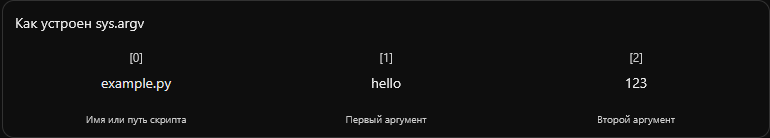


Нужно обратить внимание на два момента:

  - `sys.argv[0]` - имя или путь запускаемого скрипта
  - **Все аргументы передаются как строки**, даже если выглядят как строки


2. **Практический пример**

Создадим `calculator.py`:

``` python
import sys

a = int(sys.argv[1])
b = int(sys.argv[2])

print(a + b)
```

Теперь команда:

``` bash
python calculator.py 10 20
```

Выведет:

``` text
30
```

Но здесь есть проблема. Что произойдет, если запустить программу без аргументов?

``` bash
python calculator.py
```

Возникнет `IndexError`, поскольку `sys.argv[1]` не существует


А если запустить:

``` bash
python calculator.py hello 20
```

Возникнет `ValueError`, поскольку строку `hello` нельзя преобразовать в целое число


3. **Зачем это нужно в Harness Engineering?**

Harness должен уметь запускать команды и передавать им аргументы.

Например:

``` python
import sys
import subprocess

subprocess.run([
  sys.executable,
  "calculator.py",
  "10",
  "20"
])
```

Здесь `subprocess` создает дочерний процесс, а `sys.argv` позволяет запущенному скрипту получить переданные значения



## Урок 1.3. `sys.exit()` и коды завершения процессов

Когда программа завершается, операционная система получает специально число - **exit code** (код завершения процесса)

Обычно принято следующее соглашение:

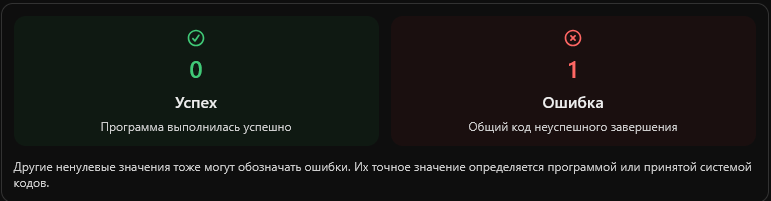

### 1. Три варианта `sys.exit()`

**Успешное завершение:**

``` python
import sys

sys.exit(0)
```


**Завершение с ошибкой:**

``` python
import sys

sys.exit(1)
```


**Завершение с текстовым сообщением:**

``` python
import sys

sys.exit("Не все параметры указаны")
```


В последнем случае Python выводит сообщение в `stderr` и завершает программу с кодом `1`

Технически `sys.exit()` возбуждает исключение `SystemExit`. Если оно не перехвачено, интерпретатор завершает работу



### 2. Как узнать код завершения?

